# 01 - Dataset Structure & Data Quality

**Owner:** Efe  |  **Branch:** `eda/data-quality`  |  **Course:** ISE308

**Goal:** get to know the UrbanEV data and check how far we can trust it before anyone builds features or models on it.

Outputs of this notebook:

| Output | File |
|---|---|
| Dataset summary table | `outputs/tables/dataset_summary.csv` |
| Missing values table | `outputs/tables/missing_values.csv` |
| Station capacity distribution figure | `outputs/figures/station_capacity_distribution.png` |
| Supporting tables / figures | everything else in `outputs/tables/` and `outputs/figures/` |

All data is read through `src/data_loader.py`, so station IDs, the timestamp grid and the development sample are the same for the whole team.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.dates as mdates

# Locate the project root (works whether the kernel starts in notebooks/ or in the root)
ROOT = Path.cwd()
if not (ROOT / "src" / "data_loader.py").exists():
    ROOT = ROOT.parent
sys.path.append(str(ROOT / "src"))
import data_loader as dl

FIG_DIR = ROOT / "outputs" / "figures"
TAB_DIR = ROOT / "outputs" / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)

BLUE, ORANGE, GRAY, INK = "#257de0", "#f47230", "#9c9c9c", "#191919"
sns.set_theme(style="whitegrid", context="notebook", rc={
    "grid.color": "#e6e6e6", "axes.edgecolor": "#cccccc", "axes.labelcolor": "#444444",
    "text.color": INK, "axes.titleweight": "bold", "axes.titlesize": 12,
    "figure.facecolor": "white", "axes.facecolor": "white"})
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

def save_table(df, name, index=False):
    df.to_csv(TAB_DIR / name, index=index)
    return df

def save_fig(fig, name):
    fig.savefig(FIG_DIR / name, dpi=200, bbox_inches="tight", facecolor="white")

DATA_ROOT = dl.get_data_root()
print("Project root:", ROOT)
print("Data root   :", DATA_ROOT)

Project root: <project>
Data root   : <project>/data/UrbanEVDataset


## 1. Dataset file structure

UrbanEV ships in two parts: the **raw station-level** data (one file per station) and a **cleaned, zone-aggregated** version (matrices of time x traffic zone). The two have different station sets, so it matters which one we use.

In [2]:
DESCRIPTIONS = {
    f"{dl.RAW_DIR_NAME}/charge_5min": "One CSV per station, 5-min time series (busy, idle, prices, fast/slow split, duration, volume)",
    f"{dl.RAW_DIR_NAME}/station_information.csv": "Station metadata: coordinates, slow/fast/total charging points, traffic zone (TAZID)",
    f"{dl.RAW_DIR_NAME}/pile_rated_power.csv": "One row per charging pile: rated power, AC/DC type, station",
    f"{dl.RAW_DIR_NAME}/station_distance.csv": "Station x station distance matrix (metres)",
    f"{dl.ZONE_DIR_NAME}/charge_5min": "Six zone-level matrices (time x TAZID) at 5-min resolution",
    f"{dl.ZONE_DIR_NAME}/charge_1hour": "The same six matrices at hourly resolution",
    f"{dl.ZONE_DIR_NAME}/station_information.csv": "Metadata of the stations kept in the cleaned version",
    f"{dl.ZONE_DIR_NAME}/zone-information.csv": "Zone metadata: centroid, charging points, area, perimeter",
    f"{dl.ZONE_DIR_NAME}/adj.csv": "Zone x zone 0/1 adjacency matrix",
    f"{dl.ZONE_DIR_NAME}/distance.csv": "Zone x zone distance matrix (metres)",
}
rows = []
for top in (dl.RAW_DIR_NAME, dl.ZONE_DIR_NAME):
    for p in sorted((DATA_ROOT / top).iterdir()):
        files = [f for f in p.rglob("*") if f.is_file()] if p.is_dir() else [p]
        rows.append({
            "path": f"{top}/{p.name}",
            "type": "folder" if p.is_dir() else "file",
            "n_files": len(files),
            "size_MB": sum(f.stat().st_size for f in files) / 1e6,
            "description": DESCRIPTIONS.get(f"{top}/{p.name}", ""),
        })
file_structure = save_table(pd.DataFrame(rows), "file_structure.csv")
file_structure

,path,type,n_files,size_MB,description
0,20220901-20230228_station-raw/charge_5min,folder,1682,"5,335.029","One CSV per station, 5-min time series (busy, ..."
1,20220901-20230228_station-raw/pile_rated_power...,file,1,0.595,"One row per charging pile: rated power, AC/DC ..."
2,20220901-20230228_station-raw/station_distance...,file,1,47.768,Station x station distance matrix (metres)
3,20220901-20230228_station-raw/station_informat...,file,1,0.064,"Station metadata: coordinates, slow/fast/total..."
4,20220901-20230228_zone-cleaned-aggregated/adj.csv,file,1,0.153,Zone x zone 0/1 adjacency matrix
5,20220901-20230228_zone-cleaned-aggregated/char...,folder,6,89.598,The same six matrices at hourly resolution
6,20220901-20230228_zone-cleaned-aggregated/char...,folder,6,"1,095.626",Six zone-level matrices (time x TAZID) at 5-mi...
7,20220901-20230228_zone-cleaned-aggregated/dist...,file,1,0.898,Zone x zone distance matrix (metres)
8,20220901-20230228_zone-cleaned-aggregated/stat...,file,1,0.046,Metadata of the stations kept in the cleaned v...
9,20220901-20230228_zone-cleaned-aggregated/zone...,file,1,0.015,"Zone metadata: centroid, charging points, area..."


The zone folder also contains six variables per resolution: `occupancy`, `duration`, `volume`, `volume-11kw`, `e_price`, `s_price`.

## 2. Verifying station, charging point and observation counts

In [3]:
raw_info = dl.load_station_info("raw")
zone_info = dl.load_station_info("zone")
zones = dl.load_zone_info()
piles = dl.load_pile_info()

raw_files = sorted(int(p.stem) for p in (dl.raw_dir() / "charge_5min").glob("*.csv"))
grid5, grid1h = dl.expected_index("5min"), dl.expected_index("1hour")

occ5 = dl.load_zone_variable("occupancy", "5min")
occ1h = dl.load_zone_variable("occupancy", "1hour")

pile_count = piles.groupby("station_id").size().rename("n_piles")
cmp = raw_info.set_index("station_id").join(pile_count).fillna({"n_piles": 0})
cmp["diff"] = cmp["charge_count"] - cmp["n_piles"]

checks = pd.DataFrame([
    ("Station files in raw/charge_5min", len(raw_files)),
    ("Stations in raw station_information.csv", len(raw_info)),
    ("File IDs == metadata IDs", raw_files == raw_info["station_id"].tolist()),
    ("Stations in zone-cleaned station_information.csv", len(zone_info)),
    ("Cleaned stations are a subset of raw stations", set(zone_info.station_id) <= set(raw_info.station_id)),
    ("Stations dropped in cleaning", len(raw_info) - len(zone_info)),
    ("Traffic zones (TAZ) with raw stations", raw_info["TAZID"].nunique()),
    ("Traffic zones in zone-information.csv", len(zones)),
    ("Zone columns in occupancy matrix", occ5.shape[1]),
    ("Zones with raw stations that are NOT in the cleaned data", raw_info["TAZID"].nunique() - len(zones)),
    ("Charging points: sum of charge_count (raw metadata)", int(raw_info["charge_count"].sum())),
    ("   of which slow", int(raw_info["slow_count"].sum())),
    ("   of which fast", int(raw_info["fast_count"].sum())),
    ("Charging points: rows in pile_rated_power.csv", len(piles)),
    ("Stations with a pile-row count != charge_count", int((cmp["diff"] != 0).sum())),
    ("   of which have no pile rows at all", int((cmp["n_piles"] == 0).sum())),
    ("5-min grid length (expected)", len(grid5)),
    ("Hourly grid length (expected)", len(grid1h)),
    ("Zone 5-min matrix index == expected grid", bool(occ5.index.equals(grid5))),
    ("Zone hourly matrix index == expected grid", bool(occ1h.index.equals(grid1h))),
], columns=["check", "value"])
checks

,check,value
0,Station files in raw/charge_5min,1682
1,Stations in raw station_information.csv,1682
2,File IDs == metadata IDs,True
3,Stations in zone-cleaned station_information.csv,1362
4,Cleaned stations are a subset of raw stations,True
5,Stations dropped in cleaning,320
6,Traffic zones (TAZ) with raw stations,331
7,Traffic zones in zone-information.csv,275
8,Zone columns in occupancy matrix,275
9,Zones with raw stations that are NOT in the cl...,56


**Reading this table**

* Station files and metadata agree (1,682 stations) and every cleaned station exists in the raw data, so IDs are safe to join on.
* The metadata says there are 24,798 charging points, but `pile_rated_power.csv` only lists 22,650 piles. **Use `charge_count` from `station_information.csv` as the capacity**; the pile file is incomplete and only useful for AC/DC and power information.
* Cleaning removed 320 stations and 56 traffic zones.

## 3. Columns and data types

In [4]:
head = pd.read_csv(dl.station_file(raw_files[0]), nrows=2000)
dtypes = lambda df: df.dtypes.astype(str).to_dict()

COL_DOC = {
 ("raw station 5-min", "time"):      "Timestamp of the 5-minute interval (start of interval)",
 ("raw station 5-min", "busy"):      "Number of charging points in use (busy + idle = station capacity)",
 ("raw station 5-min", "idle"):      "Number of charging points free",
 ("raw station 5-min", "s_price"):   "Service-fee price (unit not documented in the files; per kWh)",
 ("raw station 5-min", "e_price"):   "Electricity price (unit not documented in the files; per kWh)",
 ("raw station 5-min", "fast_busy"): "Busy fast-charging points",
 ("raw station 5-min", "fast_idle"): "Idle fast-charging points",
 ("raw station 5-min", "slow_busy"): "Busy slow-charging points",
 ("raw station 5-min", "slow_idle"): "Idle slow-charging points",
 ("raw station 5-min", "duration"):  "Charging time in the interval, in hours, summed over piles (0.083 = 5 min of one pile) [inferred from values]",
 ("raw station 5-min", "volume"):    "Energy delivered in the interval, kWh [inferred: 0.583 = 7 kW x 5 min]",
 ("station_information (raw)", "station_id"):   "Station key (int)",
 ("station_information (raw)", "longitude"):    "Longitude (WGS84)",
 ("station_information (raw)", "latitude"):     "Latitude (WGS84)",
 ("station_information (raw)", "slow_count"):   "Slow charging points",
 ("station_information (raw)", "fast_count"):   "Fast charging points",
 ("station_information (raw)", "charge_count"): "Total charging points = station capacity",
 ("station_information (raw)", "TAZID"):        "Traffic analysis zone the station belongs to",
 ("pile_rated_power", "pile_id"):    "Pile key (station_id + 4 digits)",
 ("pile_rated_power", "power"):      "Rated power (kW)",
 ("pile_rated_power", "pileType"):   "AC or DC",
 ("pile_rated_power", "station_id"): "Station key (stored as float in the CSV; loader casts to int)",
 ("zone matrices", "time"):          "Timestamp (rows)",
 ("zone matrices", "<TAZID>"):       "One column per traffic zone; values are the zone-level variable (e.g. occupancy = busy points in the zone)",
}
tables = {
    "raw station 5-min": head,
    "station_information (raw)": raw_info,
    "pile_rated_power": piles,
    "zone matrices": pd.read_csv(dl.zone_dir() / "charge_5min" / "occupancy.csv", nrows=50, usecols=range(0, 4)),
}
rows = []
for (tbl, col), desc in COL_DOC.items():
    if col == "<TAZID>":
        dt = "float64 (x 275 zone columns)"
    else:
        dt = dtypes(tables[tbl])[col]
    rows.append({"table": tbl, "column": col, "dtype_as_stored": dt, "description": desc})
column_dictionary = save_table(pd.DataFrame(rows), "column_dictionary.csv")
column_dictionary

,table,column,dtype_as_stored,description
0,raw station 5-min,time,str,Timestamp of the 5-minute interval (start of i...
1,raw station 5-min,busy,int64,Number of charging points in use (busy + idle ...
2,raw station 5-min,idle,int64,Number of charging points free
3,raw station 5-min,s_price,float64,Service-fee price (unit not documented in the ...
4,raw station 5-min,e_price,float64,Electricity price (unit not documented in the ...
5,raw station 5-min,fast_busy,int64,Busy fast-charging points
6,raw station 5-min,fast_idle,int64,Idle fast-charging points
7,raw station 5-min,slow_busy,int64,Busy slow-charging points
8,raw station 5-min,slow_idle,int64,Idle slow-charging points
9,raw station 5-min,duration,float64,"Charging time in the interval, in hours, summe..."


Note: the CSVs store `time` as text and counts as floats; the loader parses `time` to `datetime64`, casts IDs to `int` and counts/prices to `float32`.

## 4. Scan of every raw station file

One pass over all 1,682 raw files collects what we need for the next sections: duplicates, timestamp coverage, NaN structure, and the busy / idle / capacity consistency checks. Files are read **as stored** (`reindex=False`) so that nothing is hidden by the loader. This takes about a minute.

In [5]:
GRID = dl.expected_index("5min")
CAP = raw_info.set_index("station_id")[["charge_count", "fast_count", "slow_count"]]
VALUE_COLS = dl.STATION_COLUMNS
STEPS_PER_DAY = 288
N_DAYS = len(GRID) // STEPS_PER_DAY


def runs(mask):
    '''Lengths of consecutive True runs.'''
    if not mask.any():
        return np.array([], dtype=int)
    edges = np.flatnonzero(np.diff(np.r_[0, mask.astype(np.int8), 0]))
    return edges[1::2] - edges[::2]


def scan_station(sid):
    df = dl.load_station(sid, reindex=False)
    idx = df.index
    cap, fcap, scap = CAP.loc[sid]
    r = {"station_id": sid, "n_rows": len(df), "n_unique_ts": idx.nunique(),
         "n_dup_ts": int(idx.duplicated().sum()),
         "n_dup_rows": int(df.reset_index().duplicated().sum()),
         "n_missing_ts": len(GRID.difference(idx)), "n_extra_ts": len(idx.difference(GRID)),
         "sorted": bool(idx.is_monotonic_increasing)}
    for c in VALUE_COLS:
        r[f"na_{c}"] = int(df[c].isna().sum())
    valid = df["busy"].notna().to_numpy()
    r["n_valid"] = int(valid.sum())
    r["n_nan_rows"] = int((~valid).sum())
    r["nan_share"] = r["n_nan_rows"] / len(df)
    if valid.any():
        fv, lv = valid.argmax(), len(valid) - 1 - valid[::-1].argmax()
        gaps = runs(~valid[fv:lv + 1])
    else:
        fv, lv, gaps = len(valid), len(valid) - 1, np.array([], dtype=int)
    r["leading_nan"] = int(fv)
    r["trailing_nan"] = int(len(valid) - 1 - lv) if valid.any() else 0
    r["interior_nan"] = int(gaps.sum())
    r["n_interior_gaps"] = len(gaps)
    r["longest_gap"] = int(gaps.max()) if len(gaps) else 0

    v = df[valid]
    tot = v["busy"] + v["idle"]
    r["capacity"] = int(cap)
    r["n_total_ne_cap"] = int((tot != cap).sum())
    r["n_busy_gt_cap"] = int((v["busy"] > cap).sum())
    r["n_negative"] = int((v[["busy", "idle", "fast_busy", "fast_idle", "slow_busy", "slow_idle"]] < 0).sum().sum())
    r["n_noninteger"] = int((v[["busy", "idle"]] % 1 != 0).sum().sum())
    r["n_fastslow_busy_mismatch"] = int(((v["fast_busy"] + v["slow_busy"]) != v["busy"]).sum())
    r["n_fastslow_idle_mismatch"] = int(((v["fast_idle"] + v["slow_idle"]) != v["idle"]).sum())
    r["n_fast_ne_meta"] = int(((v["fast_busy"] + v["fast_idle"]) != fcap).sum())
    r["n_slow_ne_meta"] = int(((v["slow_busy"] + v["slow_idle"]) != scap).sum())
    r["n_negative_price"] = int(((v["s_price"] < 0) | (v["e_price"] < 0)).sum())
    r["mean_occupancy_rate"] = float((v["busy"] / cap).mean()) if len(v) else np.nan
    r["share_time_full"] = float((v["busy"] >= cap).mean()) if len(v) else np.nan
    r["share_time_empty"] = float((v["busy"] == 0).mean()) if len(v) else np.nan
    r["constant_busy"] = bool(v["busy"].nunique() <= 1)
    daily_valid = valid.reshape(N_DAYS, STEPS_PER_DAY).mean(axis=1)
    return r, daily_valid, gaps


results, daily, all_gaps = [], {}, []
ids = dl.list_station_ids("raw")
for k, sid in enumerate(ids, 1):
    r, d, g = scan_station(sid)
    results.append(r); daily[sid] = d; all_gaps.append(g)
    if k % 400 == 0 or k == len(ids):
        print(f"scanned {k}/{len(ids)} stations")

scan = pd.DataFrame(results).set_index("station_id")
daily_valid = pd.DataFrame(daily, index=pd.date_range(dl.START, periods=N_DAYS, freq="D")).T
gap_lengths = np.concatenate(all_gaps)
scan["in_cleaned_set"] = scan.index.isin(zone_info.station_id)
save_table(scan.reset_index(), "station_quality_scan.csv")
print(scan.shape)

scanned 400/1682 stations


scanned 800/1682 stations


scanned 1200/1682 stations


scanned 1600/1682 stations


scanned 1682/1682 stations
(1682, 40)


## 5. Duplicates and missing values

In [6]:
dup_table = pd.DataFrame([
    ("Station files with duplicated timestamps", int((scan.n_dup_ts > 0).sum()), int(scan.n_dup_ts.sum())),
    ("Station files with fully duplicated rows", int((scan.n_dup_rows > 0).sum()), int(scan.n_dup_rows.sum())),
    ("Station files not sorted by time", int((~scan["sorted"]).sum()), None),
    ("Station files with a row count != 52,128", int((scan.n_rows != len(GRID)).sum()), None),
    ("Station files with timestamps missing from the expected grid", int((scan.n_missing_ts > 0).sum()), int(scan.n_missing_ts.sum())),
    ("Station files with timestamps outside the expected grid", int((scan.n_extra_ts > 0).sum()), int(scan.n_extra_ts.sum())),
], columns=["check", "stations_affected", "rows_affected"])
dup_table

,check,stations_affected,rows_affected
0,Station files with duplicated timestamps,0,0.000
1,Station files with fully duplicated rows,0,0.000
2,Station files not sorted by time,0,NaN
3,"Station files with a row count != 52,128",0,NaN
4,Station files with timestamps missing from the...,0,0.000
5,Station files with timestamps outside the expe...,0,0.000


In [7]:
# Missing values per column, raw station files (all stations together)
total_rows = int(scan.n_rows.sum())
mv_raw = pd.DataFrame({
    "table": "raw station 5-min (1,682 files)",
    "column": VALUE_COLS,
    "n_missing": [int(scan[f"na_{c}"].sum()) for c in VALUE_COLS],
})
mv_raw["total_rows"] = total_rows
mv_raw["missing_share"] = mv_raw["n_missing"] / total_rows

# Same for zone matrices (cells)
zone_rows = []
for var in dl.ZONE_VARIABLES:
    for freq in ("5min", "1hour"):
        z = dl.load_zone_variable(var, freq)
        zone_rows.append({"table": f"zone {freq}", "column": var,
                          "n_missing": int(z.isna().sum().sum()), "total_rows": z.size,
                          "missing_share": float(z.isna().sum().sum() / z.size)})
missing_values = save_table(pd.concat([mv_raw, pd.DataFrame(zone_rows)], ignore_index=True), "missing_values.csv")
missing_values

,table,column,n_missing,total_rows,missing_share
0,"raw station 5-min (1,682 files)",busy,18555366,87679296,0.212
1,"raw station 5-min (1,682 files)",idle,18555366,87679296,0.212
2,"raw station 5-min (1,682 files)",s_price,18555366,87679296,0.212
3,"raw station 5-min (1,682 files)",e_price,18555366,87679296,0.212
4,"raw station 5-min (1,682 files)",fast_busy,18555366,87679296,0.212
5,"raw station 5-min (1,682 files)",fast_idle,18555366,87679296,0.212
6,"raw station 5-min (1,682 files)",slow_busy,18555366,87679296,0.212
7,"raw station 5-min (1,682 files)",slow_idle,18555366,87679296,0.212
8,"raw station 5-min (1,682 files)",duration,18555366,87679296,0.212
9,"raw station 5-min (1,682 files)",volume,18555366,87679296,0.212


In [8]:
all_na_rows = int(scan.n_nan_rows.sum())
same_pattern = all(scan[f"na_{c}"].equals(scan["na_busy"]) for c in VALUE_COLS)
print(f"Rows where every value column is NaN : {all_na_rows:,} of {total_rows:,} ({all_na_rows/total_rows:.1%})")
print(f"All 10 columns have exactly the same NaN count in every station: {same_pattern}")
print(f"Stations with at least one NaN row   : {(scan.n_nan_rows > 0).sum():,} of {len(scan):,}")
print(f"Stations that are 100% NaN           : {(scan.n_valid == 0).sum()}")

Rows where every value column is NaN : 18,555,366 of 87,679,296 (21.2%)
All 10 columns have exactly the same NaN count in every station: True
Stations with at least one NaN row   : 1,682 of 1,682
Stations that are 100% NaN           : 21


So the files are *complete in rows* (no duplicates, no missing timestamps) but a missing observation is stored as a **row whose 10 value columns are all NaN**. Missingness is therefore a station-level event (a station not reporting), never a single column.

### 5.1 Where do the NaN rows sit?

In [9]:
comp = pd.Series({
    "Leading (before the station's first report)": int(scan.leading_nan.sum()),
    "Interior (gaps between first and last report)": int(scan.interior_nan.sum()),
    "Trailing (after the station's last report)": int(scan.trailing_nan.sum()),
})
comp_df = pd.DataFrame({"nan_rows": comp, "share_of_all_nan": comp / comp.sum(),
                        "share_of_all_rows": comp / total_rows})
save_table(comp_df.reset_index().rename(columns={"index": "type"}), "missing_composition.csv")
display(comp_df)

bins = [-0.001, 0.0, 0.01, 0.10, 0.25, 0.50, 0.999, 1.0]
labels = ["0 %", "0-1 %", "1-10 %", "10-25 %", "25-50 %", "50-99.9 %", "100 %"]
cat = pd.cut(scan.nan_share, bins=bins, labels=labels)
dist = (pd.crosstab(cat, scan.in_cleaned_set).rename(columns={False: "dropped_in_cleaning", True: "kept_in_cleaned"})
        .assign(total=lambda d: d.sum(axis=1)))
save_table(dist.reset_index().rename(columns={"nan_share": "nan_share_bucket"}), "missing_share_by_station.csv")
display(dist)
print("Median NaN share  kept:", round(scan[scan.in_cleaned_set].nan_share.median(), 3),
      "| dropped:", round(scan[~scan.in_cleaned_set].nan_share.median(), 3))
print("Max NaN share in kept set:", round(scan[scan.in_cleaned_set].nan_share.max(), 3))

,nan_rows,share_of_all_nan,share_of_all_rows
Leading (before the station's first report),5820725,0.314,0.066
Interior (gaps between first and last report),10738628,0.579,0.122
Trailing (after the station's last report),1996013,0.108,0.023


in_cleaned_set,dropped_in_cleaning,kept_in_cleaned,total
nan_share,,,
0-1 %,6,167,173
1-10 %,27,636,663
10-25 %,11,149,160
25-50 %,105,410,515
50-99.9 %,150,0,150
100 %,21,0,21


Median NaN share  kept: 0.056 | dropped: 0.582
Max NaN share in kept set: 0.299


### 5.2 Missing timestamps and gap lengths

No timestamp is missing from the grid, so the "missing timestamps" that matter are the NaN gaps above. The next table shows how long the interior gaps are.

In [10]:
steps = {"5 min": 1, "1 hour": 12, "6 hours": 72, "1 day": 288, "1 week": 2016}
gap_summary = pd.DataFrame([
    {"gap_at_least": k, "n_gaps": int((gap_lengths >= v).sum()),
     "stations_with_such_a_gap": int((scan.longest_gap >= v).sum())}
    for k, v in steps.items()])
save_table(gap_summary, "gap_length_summary.csv")
display(gap_summary)
print(f"Interior gaps in total: {len(gap_lengths):,}; median length {np.median(gap_lengths):.0f} steps "
      f"({np.median(gap_lengths)*5/60:.1f} h); longest {gap_lengths.max():,} steps ({gap_lengths.max()/288:.1f} days)")
print(f"Median over stations of their longest interior gap: {scan.longest_gap.median():.0f} steps ({scan.longest_gap.median()/288:.1f} days)")

,gap_at_least,n_gaps,stations_with_such_a_gap
0,5 min,34368,1661
1,1 hour,29687,1564
2,6 hours,9289,1504
3,1 day,8511,1452
4,1 week,947,729


Interior gaps in total: 34,368; median length 24 steps (2.0 h); longest 10,332 steps (35.9 days)
Median over stations of their longest interior gap: 1691 steps (5.9 days)


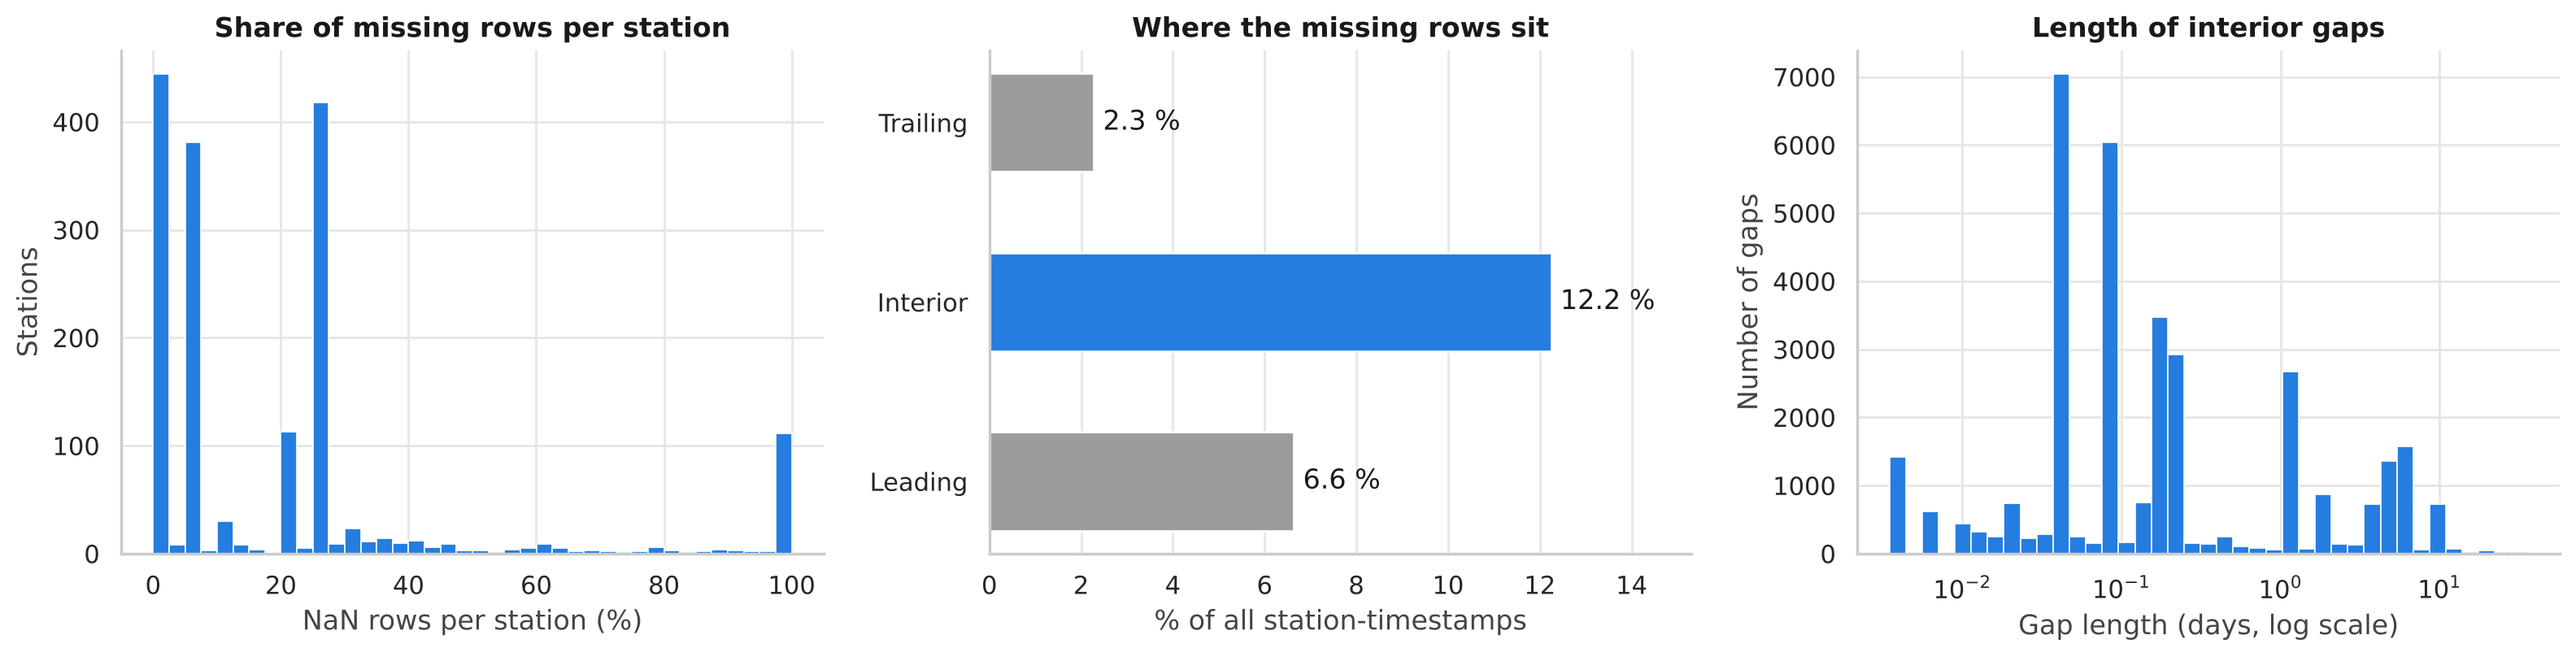

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

ax = axes[0]
ax.hist(scan.nan_share * 100, bins=40, color=BLUE, edgecolor="white", linewidth=0.6)
ax.set_xlabel("NaN rows per station (%)"); ax.set_ylabel("Stations")
ax.set_title("Share of missing rows per station")

ax = axes[1]
parts = scan[["leading_nan", "interior_nan", "trailing_nan"]].sum() / total_rows * 100
ax.barh(["Leading", "Interior", "Trailing"], parts.values, color=[GRAY, BLUE, GRAY], height=0.55)
for y, v in enumerate(parts.values):
    ax.text(v + 0.2, y, f"{v:.1f} %", va="center", color=INK)
ax.set_xlabel("% of all station-timestamps"); ax.set_title("Where the missing rows sit")
ax.set_xlim(0, parts.max() * 1.25); ax.grid(axis="y", visible=False)

ax = axes[2]
ax.hist(gap_lengths / 288, bins=np.logspace(np.log10(1 / 288), np.log10(gap_lengths.max() / 288), 40), color=BLUE, edgecolor="white", linewidth=0.6)
ax.set_xscale("log"); ax.set_xlabel("Gap length (days, log scale)"); ax.set_ylabel("Number of gaps")
ax.set_title("Length of interior gaps")
for a in axes: a.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
save_fig(fig, "missing_overview.png")
plt.show()

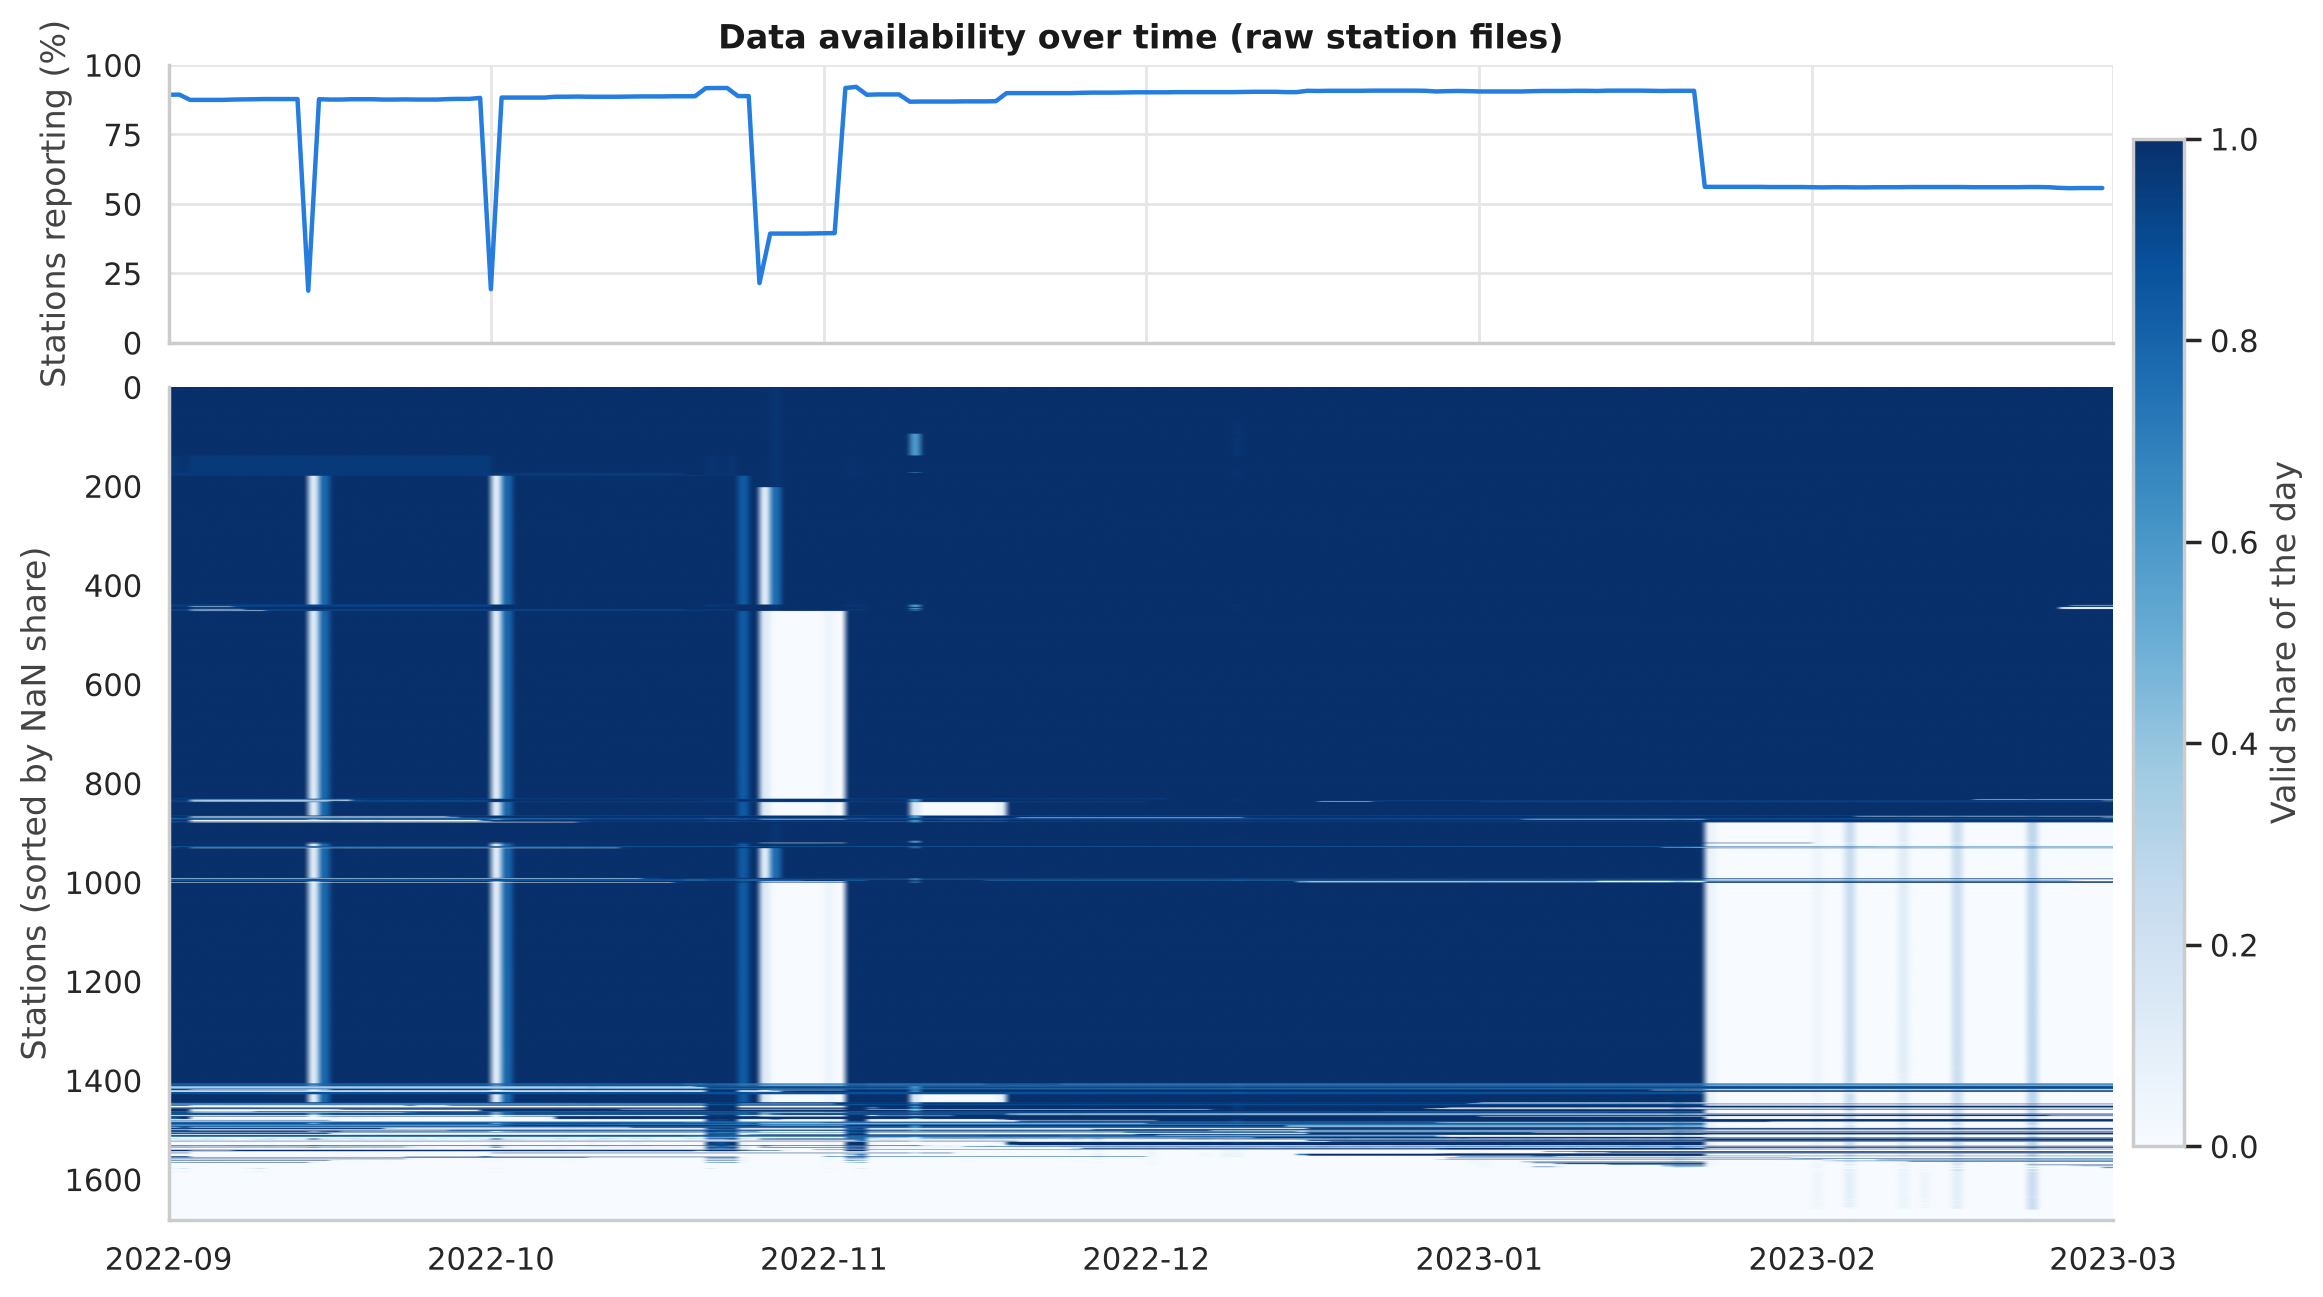

In [12]:
# Data availability over time: fraction of valid 5-min steps per station per day
order = scan.sort_values("nan_share").index
fig, (ax0, ax1) = plt.subplots(2, 1, figsize=(13, 7.5), sharex=True,
                               gridspec_kw={"height_ratios": [1, 3], "hspace": 0.08})
share_reporting = (daily_valid > 0.5).mean()
ax0.plot(share_reporting.index, share_reporting.values * 100, color=BLUE, linewidth=1.6)
ax0.set_ylabel("Stations reporting (%)"); ax0.set_ylim(0, 100)
ax0.set_title("Data availability over time (raw station files)")
im = ax1.imshow(daily_valid.loc[order].values, aspect="auto", cmap="Blues", vmin=0, vmax=1,
                extent=[mdates.date2num(daily_valid.columns[0]),
                        mdates.date2num(daily_valid.columns[-1]) + 1, len(order), 0])
ax1.xaxis_date(); ax1.set_ylabel("Stations (sorted by NaN share)")
ax1.grid(False)
cb = fig.colorbar(im, ax=[ax0, ax1], pad=0.01, fraction=0.025); cb.set_label("Valid share of the day")
for a in (ax0, ax1): a.spines[["top", "right"]].set_visible(False)
save_fig(fig, "data_availability_heatmap.png")
plt.show()

The heatmap shows that missingness is **not random**: it comes in system-wide events. The next cell locates them.

In [13]:
rep = (daily_valid > 0.5).mean()                 # share of stations reporting on each day
jumps = rep.diff()[lambda s: s.abs() > 0.15]
events = pd.DataFrame({"date": jumps.index.date, "change_in_share_reporting": jumps.values})
events["share_reporting_after"] = rep.loc[jumps.index].values
save_table(events, "reporting_events.csv")
display(events)

kept_ids = zone_info.station_id.tolist()
late = daily_valid.loc[kept_ids, "2023-01-22":]
early = daily_valid.loc[kept_ids, :"2023-01-21"]
print(f"Days with < 50 % of stations reporting: {[str(d.date()) for d in rep[rep < 0.5].index]}")
print(f"Cleaned-set stations: NaN share before 2023-01-22 = {1 - early.values.mean():.1%}, from 2023-01-22 to the end = {1 - late.values.mean():.1%}")
print(f"Cleaned-set stations that are > 50 % NaN from 2023-01-22 on: {(late.mean(axis=1) < 0.5).sum()} of {len(kept_ids)}")

,date,change_in_share_reporting,share_reporting_after
0,2022-09-14,-0.690,0.187
1,2022-09-15,0.690,0.877
2,2022-10-01,-0.689,0.193
3,2022-10-02,0.690,0.883
4,2022-10-26,-0.674,0.215
5,2022-10-27,0.178,0.393
6,2022-11-03,0.523,0.917
7,2023-01-22,-0.346,0.561


Days with < 50 % of stations reporting: ['2022-09-14', '2022-10-01', '2022-10-26', '2022-10-27', '2022-10-28', '2022-10-29', '2022-10-30', '2022-10-31', '2022-11-01', '2022-11-02']
Cleaned-set stations: NaN share before 2023-01-22 = 5.5%, from 2023-01-22 to the end = 35.9%
Cleaned-set stations that are > 50 % NaN from 2023-01-22 on: 497 of 1362


## 6. Consistency of `busy`, `idle` and station capacity

All checks use only valid rows (NaN rows are excluded, otherwise every comparison would fail trivially).

In [14]:
n_valid_total = int(scan.n_valid.sum())
def row(name, col):
    return {"check": name, "rows_violating": int(scan[col].sum()),
            "stations_violating": int((scan[col] > 0).sum()), "valid_rows_checked": n_valid_total}
cons = pd.DataFrame([
    row("busy + idle != charge_count (station capacity)", "n_total_ne_cap"),
    row("busy > charge_count", "n_busy_gt_cap"),
    row("negative busy / idle / fast / slow counts", "n_negative"),
    row("non-integer busy or idle", "n_noninteger"),
    row("fast_busy + slow_busy != busy", "n_fastslow_busy_mismatch"),
    row("fast_idle + slow_idle != idle", "n_fastslow_idle_mismatch"),
    row("fast_busy + fast_idle != fast_count (metadata)", "n_fast_ne_meta"),
    row("slow_busy + slow_idle != slow_count (metadata)", "n_slow_ne_meta"),
    row("negative price", "n_negative_price"),
])
cons["verdict"] = np.where(cons.rows_violating == 0, "OK", "CHECK")
save_table(cons, "consistency_checks.csv")
cons

,check,rows_violating,stations_violating,valid_rows_checked,verdict
0,busy + idle != charge_count (station capacity),0,0,69123930,OK
1,busy > charge_count,0,0,69123930,OK
2,negative busy / idle / fast / slow counts,0,0,69123930,OK
3,non-integer busy or idle,0,0,69123930,OK
4,fast_busy + slow_busy != busy,0,0,69123930,OK
5,fast_idle + slow_idle != idle,0,0,69123930,OK
6,fast_busy + fast_idle != fast_count (metadata),188065,4,69123930,CHECK
7,slow_busy + slow_idle != slow_count (metadata),188065,4,69123930,CHECK
8,negative price,0,0,69123930,OK


In [15]:
bad = scan[scan.n_slow_ne_meta > 0][["capacity"]].join(CAP[["fast_count", "slow_count"]]).join(scan[["n_slow_ne_meta", "n_valid"]])
print("Stations whose fast/slow split in the time series contradicts the metadata:")
display(bad)
sample_row = dl.load_station(bad.index[0]).dropna().iloc[0][["busy", "idle", "fast_busy", "fast_idle", "slow_busy", "slow_idle"]]
print(f"Example (station {bad.index[0]}):"); print(sample_row.to_string())

Stations whose fast/slow split in the time series contradicts the metadata:


,capacity,fast_count,slow_count,n_slow_ne_meta,n_valid
station_id,,,,,
1259,8,8,0,51138,51138
1955,3,3,0,49200,49200
2233,2,2,0,49200,49200
2239,4,4,0,38527,38527


Example (station 1259):
busy        4.000
idle        4.000
fast_busy   0.000
fast_idle   0.000
slow_busy   4.000
slow_idle   4.000


`busy + idle` equals the station capacity in **every valid row**, so occupancy rate `busy / charge_count` and availability `idle` are exactly consistent. The only inconsistency is 4 stations whose metadata says all points are "fast" while the time series reports them as "slow"; total `busy`/`idle` are unaffected.

### 6.1 Suspicious stations

In [16]:
susp = pd.DataFrame([
    ("100 % NaN (never report)", int((scan.n_valid == 0).sum())),
    ("Report but `busy` never changes", int(((scan.constant_busy) & (scan.n_valid > 0)).sum())),
    ("Empty (busy == 0) more than 90 % of the time", int((scan.share_time_empty > 0.9).sum())),
    ("Full (busy == capacity) more than 50 % of the time", int((scan.share_time_full > 0.5).sum())),
    ("Share of valid observations where the station is completely full", float(((scan.share_time_full * scan.n_valid).sum()) / scan.n_valid.sum())),
], columns=["check", "value"])
save_table(susp, "suspicious_stations.csv")
susp

,check,value
0,100 % NaN (never report),21.000
1,Report but `busy` never changes,6.000
2,Empty (busy == 0) more than 90 % of the time,80.000
3,Full (busy == capacity) more than 50 % of the ...,49.000
4,Share of valid observations where the station ...,0.043


## 7. Raw vs cleaned zone data

The cleaned version is what most of us will model on, so it is worth knowing what "cleaned" did.

In [17]:
kept, dropped = scan[scan.in_cleaned_set], scan[~scan.in_cleaned_set]
cmp_clean = pd.DataFrame({
    "stations": [len(kept), len(dropped)],
    "median_nan_share": [kept.nan_share.median(), dropped.nan_share.median()],
    "max_nan_share": [kept.nan_share.max(), dropped.nan_share.max()],
    "stations_over_50pct_nan": [int((kept.nan_share > .5).sum()), int((dropped.nan_share > .5).sum())],
    "median_capacity": [kept.capacity.median(), dropped.capacity.median()],
}, index=["kept in cleaned set", "dropped"])
save_table(cmp_clean.reset_index().rename(columns={"index": "group"}), "raw_vs_cleaned_stations.csv")
display(cmp_clean)

# How do zone matrices relate to the raw busy counts? Compare a few zones with a single station.
single = zone_info.groupby("TAZID").filter(lambda g: len(g) == 1).sort_values("TAZID")
rows = []
for _, s in single.head(12).iterrows():
    raw_busy = dl.load_station(int(s.station_id), ["busy"])["busy"]
    z = occ5[int(s.TAZID)]
    v = raw_busy.notna()
    rows.append({"TAZID": int(s.TAZID), "station_id": int(s.station_id),
                 "raw_nan_share": 1 - v.mean(),
                 "share_equal_where_raw_valid": float(np.isclose(raw_busy[v], z[v]).mean()),
                 "zone_nan": int(z.isna().sum()),
                 "mean_zone_value_where_raw_nan": float(z[~v].mean()) if (~v).any() else np.nan})
zone_vs_raw = save_table(pd.DataFrame(rows), "zone_vs_raw_single_station_zones.csv")
display(zone_vs_raw)

# 1-hour vs 5-min
top = occ5.loc[occ1h.index]
print("Hourly occupancy equals the 5-min value at the top of the hour in "
      f"{np.isclose(top.values, occ1h.values).mean():.2%} of cells; "
      f"equals the hourly mean in {np.isclose(occ5.resample('1h').mean().values, occ1h.values).mean():.2%}.")

# zone capacity
cap_kept = zone_info.groupby("TAZID").charge_count.sum()
zc = zones.set_index("TAZID")["charge_count"]
print(f"zone-information.csv charge_count == sum over CLEANED stations in {np.mean(zc == cap_kept.reindex(zc.index)):.0%} of zones "
      f"(it matches the sum over ALL raw stations in {np.mean(zc == raw_info.groupby('TAZID').charge_count.sum().reindex(zc.index)):.0%}).")
print(f"Zone occupancy > capacity of its cleaned stations in {(occ5.values > cap_kept.reindex(occ5.columns).values).mean():.3%} of zone-timestamps; "
      f"> zone-information capacity in {(occ5.values > zc.reindex(occ5.columns).values).mean():.3%}.")

,stations,median_nan_share,max_nan_share,stations_over_50pct_nan,median_capacity
kept in cleaned set,1362,0.056,0.299,0,10.000
dropped,320,0.582,1.000,171,15.000


,TAZID,station_id,raw_nan_share,share_equal_where_raw_valid,zone_nan,mean_zone_value_where_raw_nan
0,310,1220,0.019,1.000,0,2.630
1,316,1268,0.056,1.000,0,1.689
2,323,1477,0.072,1.000,0,2.783
3,340,1522,0.007,0.988,0,8.702
4,343,1582,0.013,0.997,0,2.516
5,348,1484,0.056,0.998,0,3.197
6,516,1155,0.002,1.000,0,37.000
7,553,1016,0.205,0.893,0,3.746
8,559,1001,0.205,1.000,0,7.549
9,568,1176,0.205,1.000,0,8.901


Hourly occupancy equals the 5-min value at the top of the hour in 99.80% of cells; equals the hourly mean in 43.59%.
zone-information.csv charge_count == sum over CLEANED stations in 56% of zones (it matches the sum over ALL raw stations in 100%).
Zone occupancy > capacity of its cleaned stations in 0.000% of zone-timestamps; > zone-information capacity in 0.000%.


The zone files have **no NaN at all**: gaps in the raw stations were filled with plausible values (not zeros), and the cleaning also changed some *observed* values (in 5 of the 12 single-station zones above, 0.2-11 % of the valid raw values differ from the zone value). Hourly tables are the **snapshot at the start of each hour**, not an hourly average. `zone-information.csv` reports capacity summed over *all* raw stations of the zone, so for 44 % of zones it is larger than the capacity of the stations that remain in the cleaned data; for an occupancy rate use the sum of `charge_count` over the cleaned stations (`zone_info.groupby("TAZID").charge_count.sum()`).

## 8. Station capacity distribution

In [18]:
cap = raw_info.set_index("station_id")["charge_count"]
cap_stats = cap.describe(percentiles=[.1, .25, .5, .75, .9, .99]).to_frame("charge_count")
display(cap_stats)

cats = pd.cut(cap, [0, 5, 10, 20, 50, 200], labels=["1-5", "6-10", "11-20", "21-50", "51+"])
cat_table = (pd.DataFrame({"stations": cats.value_counts().sort_index(),
                           "charging_points": cap.groupby(cats, observed=False).sum()})
             .assign(share_of_stations=lambda d: d.stations / d.stations.sum(),
                     share_of_points=lambda d: d.charging_points / d.charging_points.sum()))
save_table(cat_table.reset_index().rename(columns={"charge_count": "capacity_bucket", "index": "capacity_bucket"}), "station_capacity_buckets.csv")
display(cat_table)

fast_share = raw_info.fast_count.sum() / raw_info.charge_count.sum()
n_fast_only = int((raw_info.slow_count == 0).sum()); n_slow_only = int((raw_info.fast_count == 0).sum())
print(f"Fast points: {fast_share:.1%} of all points | stations with only fast points: {n_fast_only} | only slow: {n_slow_only}")

,charge_count
count,"1,682.000"
mean,14.743
std,15.505
min,1.000
10%,3.000
25%,6.000
50%,10.000
75%,18.000
90%,34.000
99%,79.190


,stations,charging_points,share_of_stations,share_of_points
charge_count,,,,
1-5,332,1032,0.197,0.042
6-10,516,3631,0.307,0.146
11-20,510,7093,0.303,0.286
21-50,256,8206,0.152,0.331
51+,68,4836,0.040,0.195


Fast points: 14.7% of all points | stations with only fast points: 121 | only slow: 1516


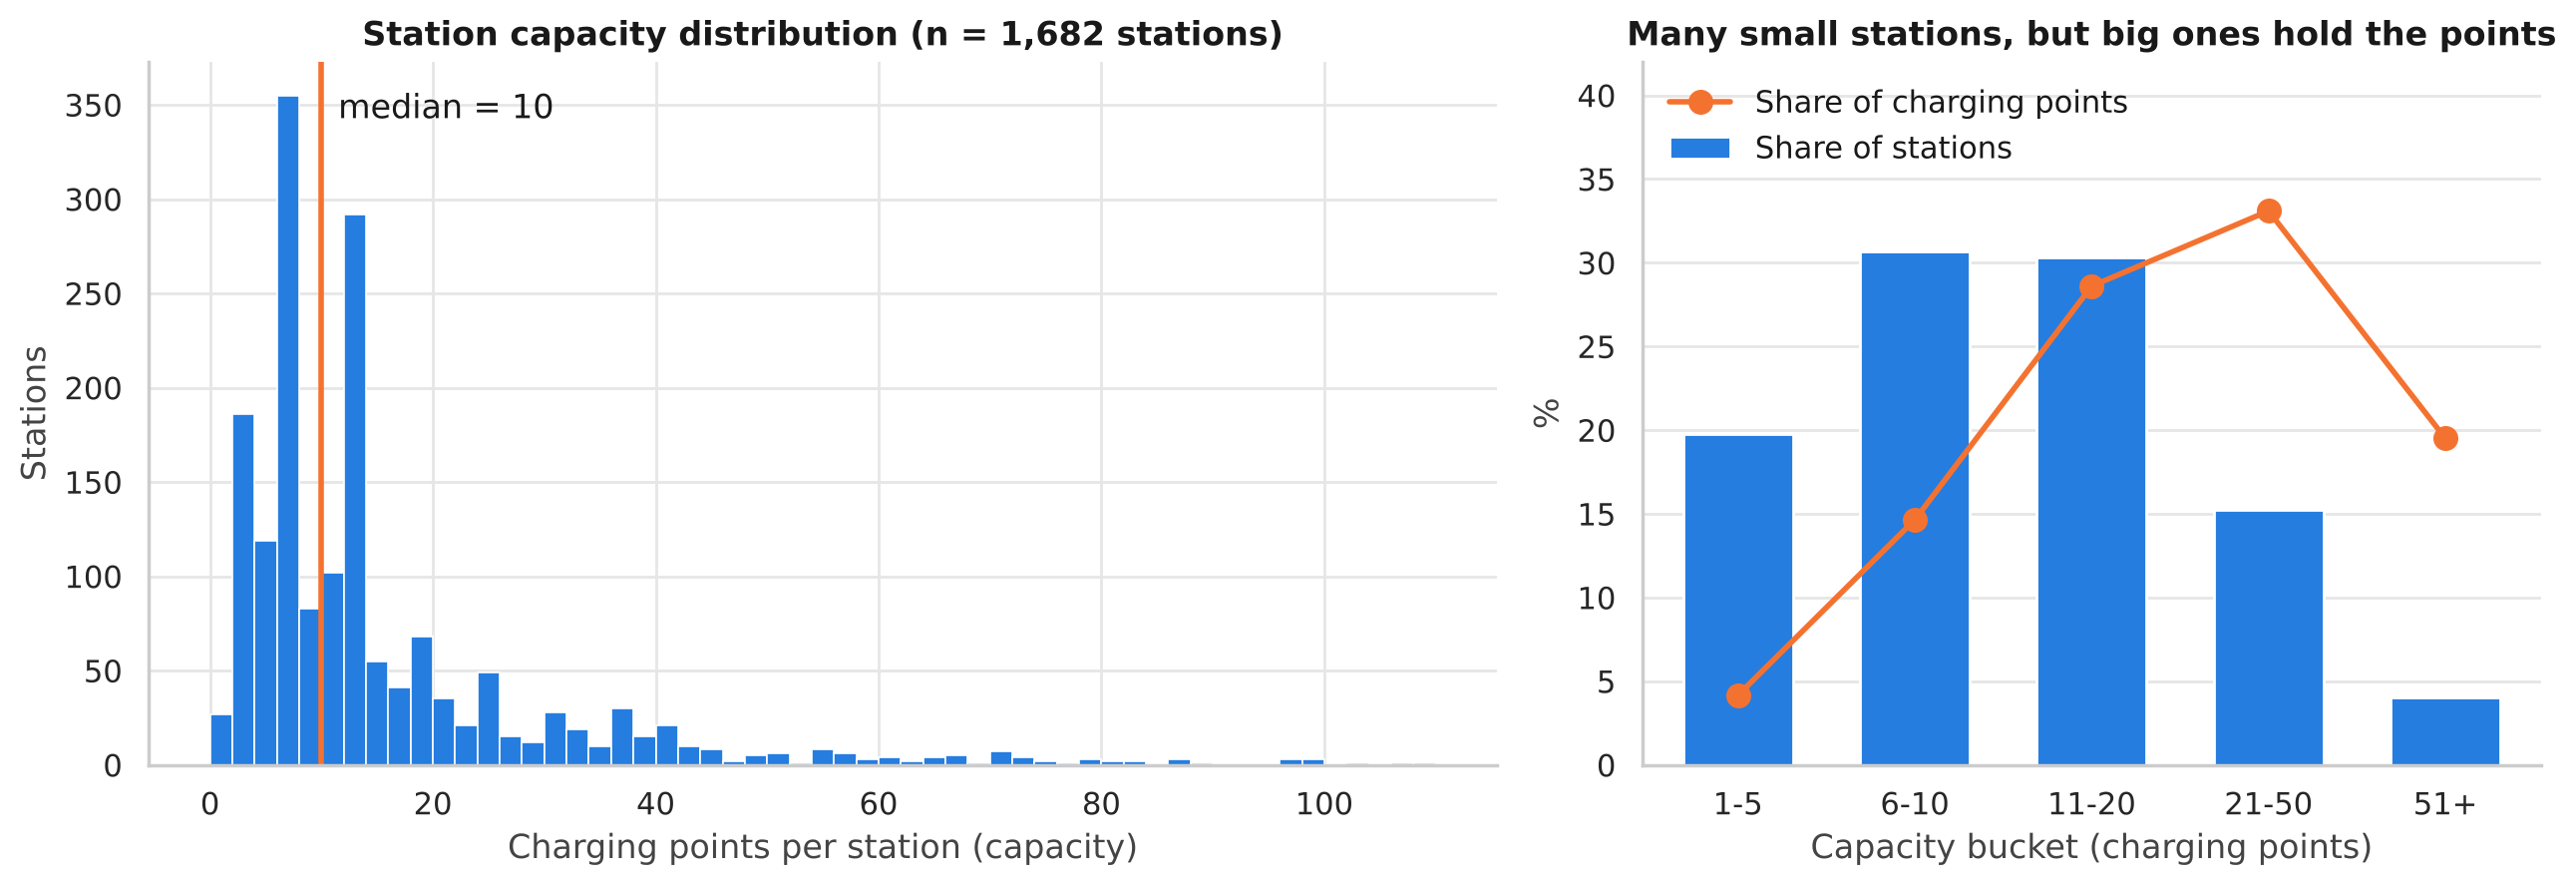

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
ax.hist(cap, bins=np.arange(0, cap.max() + 4, 2), color=BLUE, edgecolor="white", linewidth=0.6)
ax.axvline(cap.median(), color=ORANGE, linewidth=2)
ax.text(cap.median() + 1.5, ax.get_ylim()[1] * 0.92, f"median = {cap.median():.0f}", color=INK)
ax.set_xlabel("Charging points per station (capacity)"); ax.set_ylabel("Stations")
ax.set_title(f"Station capacity distribution (n = {len(cap):,} stations)")

ax = axes[1]
ax.bar(cat_table.index.astype(str), cat_table.share_of_stations * 100, color=BLUE, width=0.62, label="Share of stations")
ax.plot(cat_table.index.astype(str), cat_table.share_of_points * 100, color=ORANGE, marker="o", markersize=8, linewidth=2, label="Share of charging points")
ax.set_xlabel("Capacity bucket (charging points)"); ax.set_ylabel("%")
ax.set_title("Many small stations, but big ones hold the points"); ax.set_ylim(0, 42); ax.legend(frameon=False, loc="upper left")
ax.grid(axis="x", visible=False)
for a in axes: a.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
save_fig(fig, "station_capacity_distribution.png")
plt.show()

## 9. Geographic distribution

Bounding box: lon 113.785 - 114.517 | lat 22.466 - 22.819
Stations sharing exact coordinates with another station: 264 (in 125 locations)
Stations per zone: median 4.0 | max 42 | zones with a single station: 69
Zone capacity (cleaned stations): median 48.0 | max 373
Top 10 zones hold 12.8% of all charging points


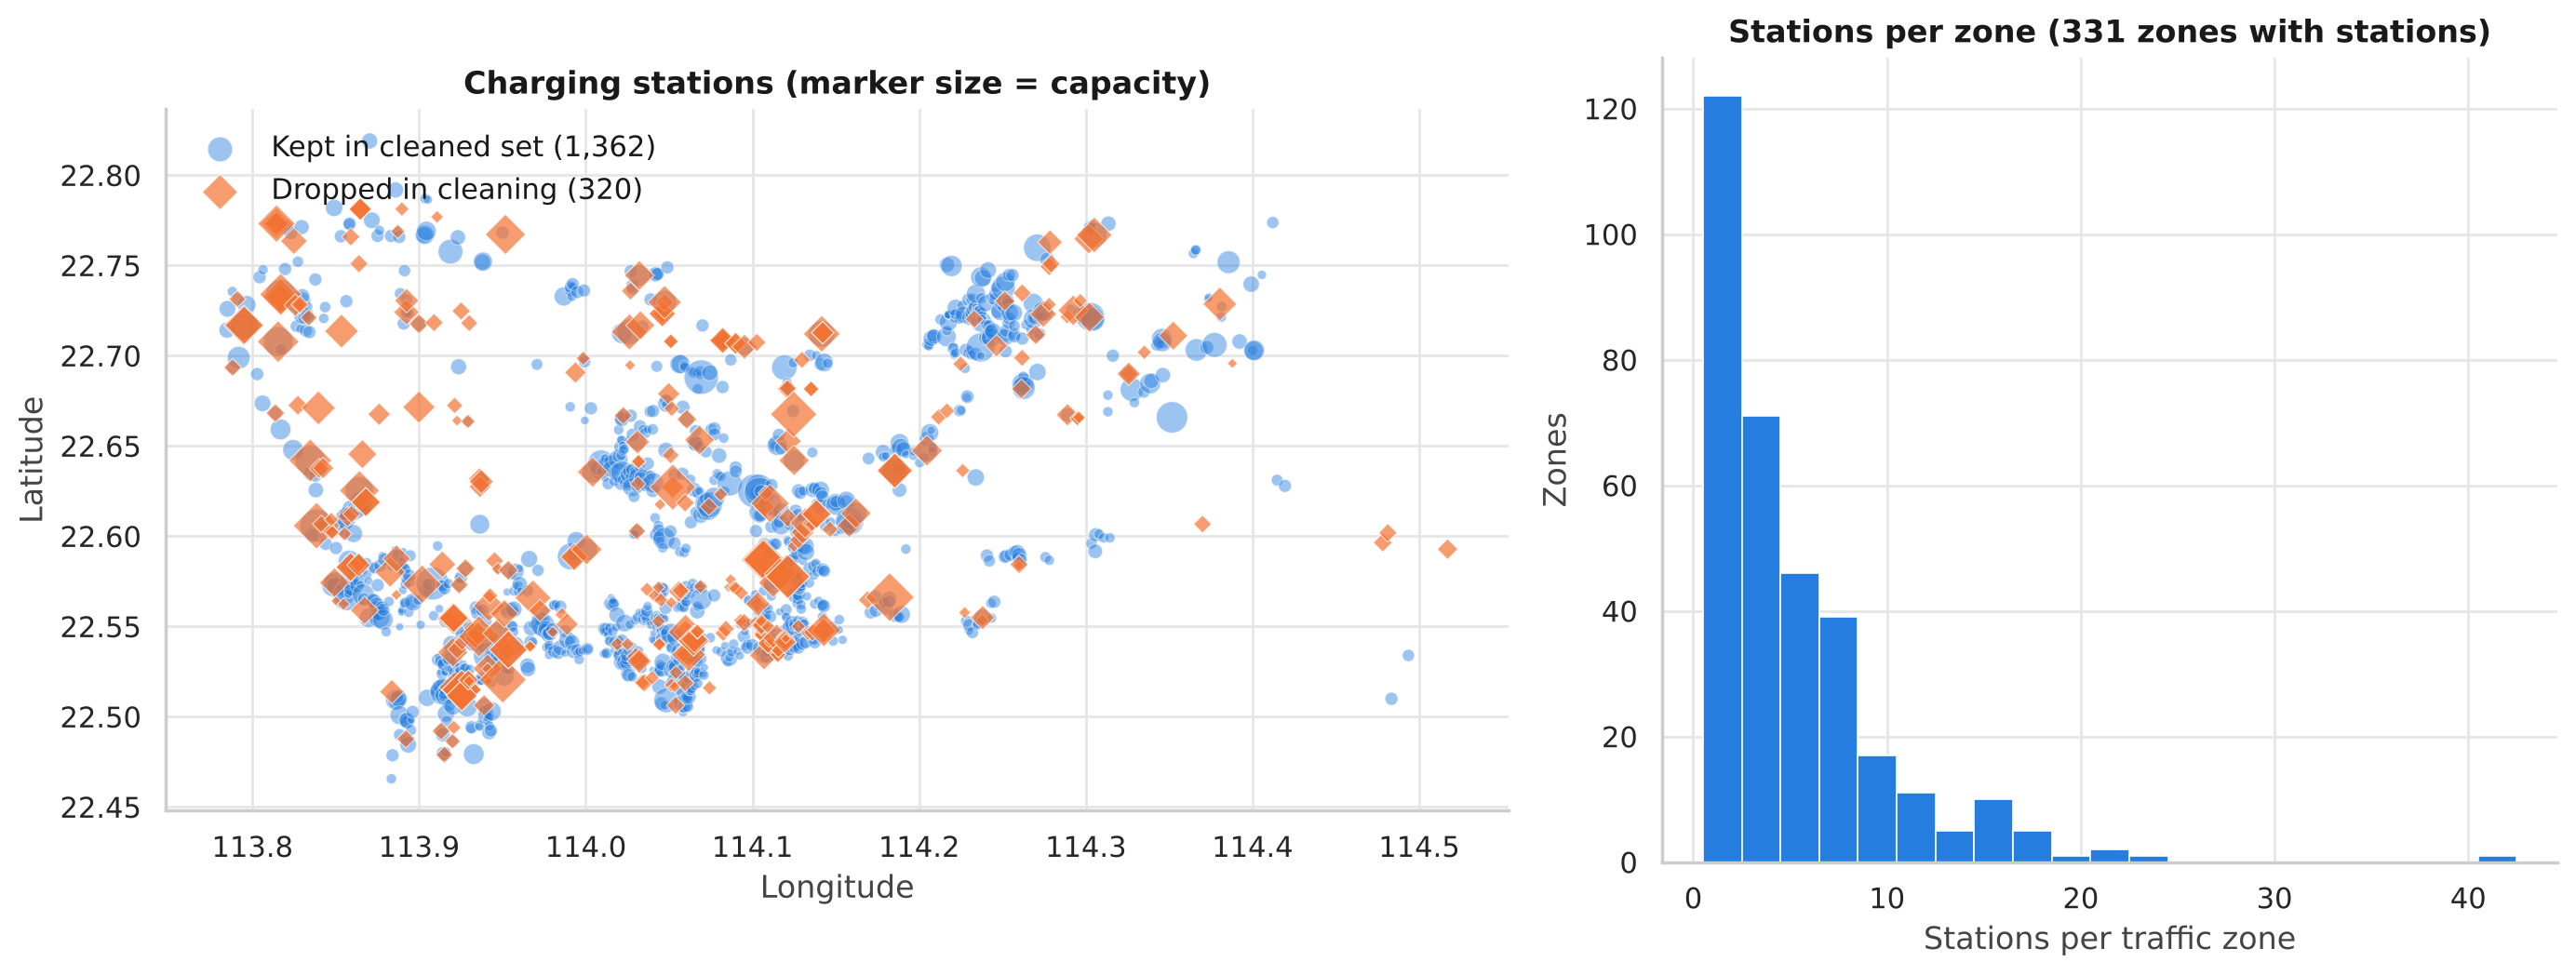

In [20]:
geo = raw_info.merge(scan[["nan_share", "in_cleaned_set"]], left_on="station_id", right_index=True)
print("Bounding box: lon", round(geo.longitude.min(), 3), "-", round(geo.longitude.max(), 3),
      "| lat", round(geo.latitude.min(), 3), "-", round(geo.latitude.max(), 3))
print("Stations sharing exact coordinates with another station:", int(geo.duplicated(["longitude", "latitude"], keep=False).sum()),
      f"(in {geo[geo.duplicated(['longitude','latitude'], keep=False)].groupby(['longitude','latitude']).ngroups} locations)")
per_zone = raw_info.groupby("TAZID").size()
print("Stations per zone: median", per_zone.median(), "| max", per_zone.max(), "| zones with a single station:", int((per_zone == 1).sum()))
cap_zone = zone_info.groupby("TAZID").charge_count.sum()
print("Zone capacity (cleaned stations): median", cap_zone.median(), "| max", cap_zone.max())
top_zones = (raw_info.groupby("TAZID").agg(stations=("station_id", "size"), charging_points=("charge_count", "sum"))
             .sort_values("charging_points", ascending=False))
top_zones["share_of_points"] = top_zones.charging_points / top_zones.charging_points.sum()
save_table(top_zones.reset_index(), "zone_capacity_ranking.csv")
print(f"Top 10 zones hold {top_zones.head(10).share_of_points.sum():.1%} of all charging points")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.4), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
d = geo[~geo.in_cleaned_set]; k = geo[geo.in_cleaned_set]
sc = ax.scatter(k.longitude, k.latitude, s=k.charge_count * 1.6 + 6, c=BLUE, alpha=0.45, edgecolor="white", linewidth=0.4, label=f"Kept in cleaned set ({len(k):,})")
ax.scatter(d.longitude, d.latitude, s=d.charge_count * 1.6 + 6, c=ORANGE, alpha=0.7, edgecolor="white", linewidth=0.4, marker="D", label=f"Dropped in cleaning ({len(d):,})")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude"); ax.set_aspect(1 / np.cos(np.deg2rad(geo.latitude.mean())))
ax.set_title("Charging stations (marker size = capacity)"); ax.legend(frameon=False, loc="upper left")
ax = axes[1]
ax.hist(per_zone, bins=np.arange(0.5, per_zone.max() + 1.5, 2), color=BLUE, edgecolor="white", linewidth=0.6)
ax.set_xlabel("Stations per traffic zone"); ax.set_ylabel("Zones"); ax.set_title(f"Stations per zone ({len(per_zone)} zones with stations)")
for a in axes: a.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
save_fig(fig, "station_map.png")
plt.show()

## 10. The shared development sample

Everyone develops on `dl.get_sample_station_ids()` (50 stations, seed 42, drawn from the cleaned set) and applies the final analysis to the full data. Let's check that this sample is not misleading.

In [21]:
sample_ids = dl.get_sample_station_ids()
pop = scan[scan.in_cleaned_set]
smp = scan.loc[sample_ids]
cmp_s = pd.DataFrame({
    "cleaned population (1,362)": [pop.capacity.median(), pop.capacity.mean(), pop.capacity.max(), pop.nan_share.median(), pop.nan_share.max(), pop.mean_occupancy_rate.mean()],
    "shared sample (50)":         [smp.capacity.median(), smp.capacity.mean(), smp.capacity.max(), smp.nan_share.median(), smp.nan_share.max(), smp.mean_occupancy_rate.mean()],
}, index=["median capacity", "mean capacity", "max capacity", "median NaN share", "max NaN share", "mean occupancy rate"])
display(cmp_s)
save_table(pd.DataFrame({"station_id": sample_ids}), "sample_stations.csv")
print("Sample IDs:", sample_ids)

,"cleaned population (1,362)",shared sample (50)
median capacity,10.000,7.500
mean capacity,12.872,9.800
max capacity,106.000,42.000
median NaN share,0.056,0.056
max NaN share,0.299,0.299
mean occupancy rate,0.256,0.268


Sample IDs: [1018, 1072, 1075, 1087, 1093, 1123, 1217, 1235, 1247, 1250, 1258, 1272, 1293, 1323, 1363, 1409, 1418, 1525, 1563, 1570, 1574, 1583, 1605, 1630, 1672, 1698, 1705, 1748, 1859, 1869, 1878, 1916, 1962, 1965, 2069, 2075, 2076, 2157, 2185, 2293, 2374, 2395, 2409, 2431, 2492, 2495, 2520, 2524, 2618, 2643]


The sample matches the cleaned population on data coverage and mean occupancy, but it **under-represents large stations** (largest sample station: 42 points vs 106 in the population). That is fine for testing code; do not draw conclusions about large stations from the sample.

## 11. Dataset summary table

In [22]:
s_raw = scan
summary = pd.DataFrame([
    ("General", "Source", "UrbanEV (charging stations in Shenzhen)"),
    ("General", "Period", f"{GRID[0]:%Y-%m-%d} to {GRID[-1]:%Y-%m-%d} ({N_DAYS} days)"),
    ("Raw station data", "Resolution", "5 minutes"),
    ("Raw station data", "Time steps per station", f"{len(GRID):,}"),
    ("Raw station data", "Stations", f"{len(raw_info):,}"),
    ("Raw station data", "Charging points (sum of charge_count)", f"{int(raw_info.charge_count.sum()):,}"),
    ("Raw station data", "  slow / fast points", f"{int(raw_info.slow_count.sum()):,} / {int(raw_info.fast_count.sum()):,}"),
    ("Raw station data", "Charging points listed in pile_rated_power.csv", f"{len(piles):,}"),
    ("Raw station data", "Station-timestamp rows", f"{total_rows:,}"),
    ("Raw station data", "Rows with real observations", f"{n_valid_total:,} ({n_valid_total/total_rows:.1%})"),
    ("Raw station data", "All-NaN rows (missing observations)", f"{all_na_rows:,} ({all_na_rows/total_rows:.1%})"),
    ("Raw station data", "Duplicated timestamps / missing timestamps", f"{int(scan.n_dup_ts.sum())} / {int(scan.n_missing_ts.sum())}"),
    ("Raw station data", "Stations 100 % NaN", f"{int((scan.n_valid == 0).sum())}"),
    ("Raw station data", "Capacity: median / mean / max (points per station)", f"{cap.median():.0f} / {cap.mean():.1f} / {cap.max()}"),
    ("Raw station data", "Traffic zones with stations", f"{raw_info.TAZID.nunique()}"),
    ("Cleaned zone data", "Stations kept", f"{len(zone_info):,}"),
    ("Cleaned zone data", "Traffic zones", f"{occ5.shape[1]}"),
    ("Cleaned zone data", "Matrix shape 5-min / hourly (time x zone)", f"{occ5.shape} / {occ1h.shape}"),
    ("Cleaned zone data", "Variables", ", ".join(dl.ZONE_VARIABLES)),
    ("Cleaned zone data", "Missing values", "0"),
    ("Consistency", "busy + idle == charge_count", "holds in 100 % of valid rows"),
], columns=["section", "metric", "value"])
dataset_summary = save_table(summary, "dataset_summary.csv")
dataset_summary

,section,metric,value
0,General,Source,UrbanEV (charging stations in Shenzhen)
1,General,Period,2022-09-01 to 2023-02-28 (181 days)
2,Raw station data,Resolution,5 minutes
3,Raw station data,Time steps per station,"52,128"
4,Raw station data,Stations,"1,682"
5,Raw station data,Charging points (sum of charge_count),"24,798"
6,Raw station data,slow / fast points,"21,165 / 3,633"
7,Raw station data,Charging points listed in pile_rated_power.csv,"22,650"
8,Raw station data,Station-timestamp rows,"87,679,296"
9,Raw station data,Rows with real observations,"69,123,930 (78.8%)"


## 12. Key findings and implications for machine learning

**Findings**

1. **Structure is clean, content has gaps.** Every raw station file has all 52,128 five-minute timestamps, no duplicates and no unsorted rows. But **21.2 % of station-timestamps are all-NaN rows** (a station not reporting), in every one of the 10 value columns at once. 21 stations never report at all.
2. **Gaps are long, not random.** Of the NaN rows, 31 % are leading (station not yet online), 11 % trailing, and 58 % interior gaps. The median station has its longest interior gap at ~5.9 days, and 729 stations have a gap longer than a week. Short-gap interpolation will not fix this.
3. **Missingness comes in system-wide events.** Reporting collapses on 2022-09-14, 2022-10-01 and 2022-10-26 (only ~20 % of stations report on those days), 39 % of stations report from 2022-10-27 until 2022-11-02, and **on 2023-01-22 the share of reporting stations drops from 91 % to 56 % and never recovers**. For the cleaned-set stations, NaN share is 5.5 % before that date and 35.9 % after it (497 of 1,362 stations are more than 50 % NaN in the last 38 days).
4. **The dataset authors' cleaning is substantial.** The 320 dropped stations have a median 58 % NaN versus 5.6 % for the kept ones; the cleaned zone matrices have no NaN (gaps filled, not zeroed) and some observed values differ from the raw ones.
5. **busy / idle / capacity are perfectly consistent**: `busy + idle = charge_count` in every valid row, with no negatives or non-integers. Only 4 stations have a fast/slow split that contradicts the metadata (metadata: all fast, time series: all slow).
6. **Capacity is highly skewed**: median 10 points, mean 14.7, max 108; many small stations, but large stations hold a disproportionate share of points.
7. **Charging-point counts disagree between files**: 24,798 in station metadata vs 22,650 rows in the pile file.
8. **Space**: stations span about 0.73 deg of longitude and 0.35 deg of latitude; 264 stations share exact coordinates with at least one other station (125 locations), and 69 of the 331 zones contain a single station.
9. **Zone capacity pitfall**: `zone-information.csv` counts points of dropped stations too.

**Implications for Step 2 (modelling)**

* **Never train or evaluate on NaN rows.** Build the target only from valid rows (`dl.valid_mask`) or use the cleaned zone matrices. Do not forward-fill raw station data across long gaps.
* **Pick the data level deliberately.** Zone-cleaned data is ready to use but is zone-level; station-level modelling needs the raw files plus a coverage filter (for example keep stations with <= 30 % NaN, which is exactly the range of the cleaned set).
* **Define the target as an occupancy rate or as `idle` (availability)**; the exact `busy + idle = capacity` identity means either can be derived from the other without leakage or rounding problems. Use rates when pooling stations of different size.
* **Use station capacity (`charge_count`) as a static feature** and `fast_count / charge_count` as a second one; capacity varies by two orders of magnitude.
* **Split by time, not at random** and keep the same split for everyone. **Be careful with the last 38 days (from 2023-01-22):** over a third of the cleaned-set station data there is missing in the raw files, so the zone matrices contain imputed values for it. A test set taken from that period partly evaluates the imputation, not real behaviour. Either end the evaluation window on 2023-01-21, or evaluate with the raw `valid_mask`.
* **Use `charge_count` summed over cleaned stations** as the zone capacity denominator.
* **Spatial features** (zone adjacency, distance matrices) are ready in the loader; in the 69 single-station zones, zone-level and station-level series describe the same place.